# Phase 3 · Model 3 — Demand forecasting (total orders)

**Goal:** predict how many orders will arrive in the **next hour**, to plan charging, robot
positioning and staff. (`05_demand_breakdown.ipynb` forecasts **where** and **which priority**.)

**Data:** `data/processed/classical_ml/demand_hourly.parquet` — 2,184 hours (91 days × 24).

Workflow: 1 Understand → 2 Explore → 3 Target + features → 4 Split → 5 Preprocess → 6 Baseline →
7 Train → 8 Validate & tune → 9 Test once → 10 Save & report.

## Step 1 — Understand the problem

| Question | Answer |
|---|---|
| What do we predict? | `orders_total` in an hour |
| When? | Just before the hour starts: only past hours are known |
| Problem type | **Time-series regression** |
| How do we judge it? | **MAE** (orders per hour), against the "same hour last week" baseline |

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the project root (the folder that contains data/processed), wherever the notebook runs.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "data" / "processed" / "classical_ml"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60)
print("Data folder:", DATA)

Data folder: H:\ai-warehouse-platform\data\processed\classical_ml


## Step 2 — Explore the data

The whole series: daily rhythm, weekends and the November peak.

(2184, 41)


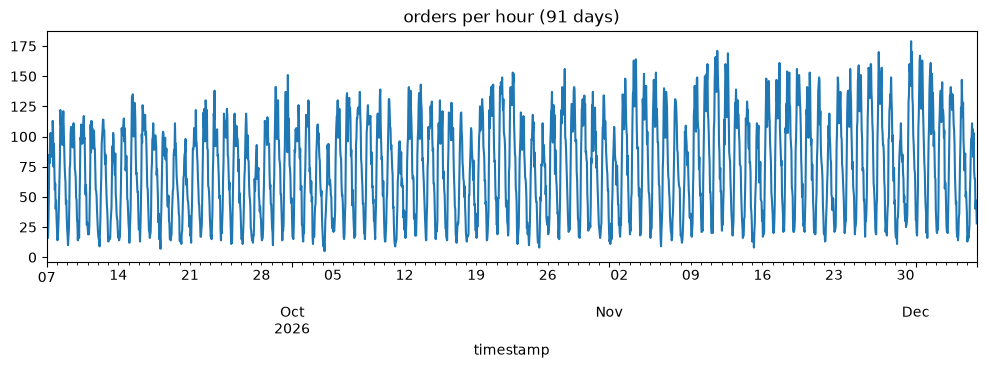

In [2]:
df = pd.read_parquet(DATA / "demand_hourly.parquet").sort_values("timestamp").reset_index(drop=True)
print(df.shape)
df.set_index("timestamp")["orders_total"].plot(figsize=(12, 3), title="orders per hour (91 days)")
plt.show()

Average shape of a day and of a week: the patterns the model must learn.

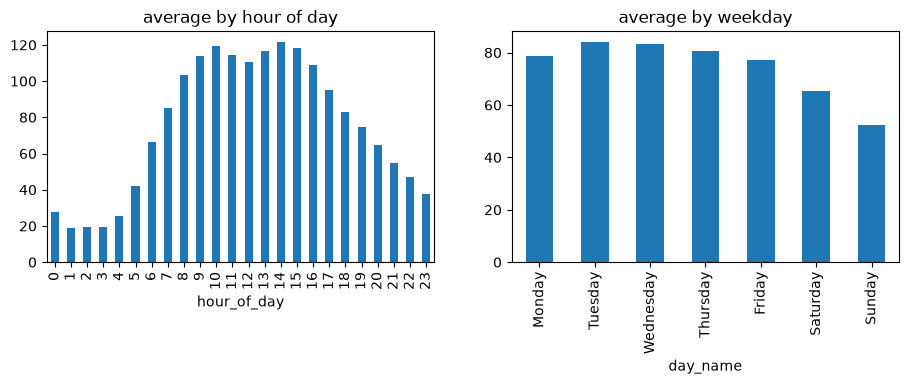

,orders_total,lag_1h_orders,lag_24h_orders,lag_168h_orders
orders_total,1.000,0.919,0.885,0.952
lag_1h_orders,0.919,1.000,0.843,0.908
lag_24h_orders,0.885,0.843,1.000,0.882
lag_168h_orders,0.952,0.908,0.882,1.000


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
df.groupby("hour_of_day")["orders_total"].mean().plot.bar(ax=ax[0], title="average by hour of day")
df.groupby("day_name", sort=False)["orders_total"].mean().plot.bar(ax=ax[1], title="average by weekday")
plt.show()
df[["orders_total", "lag_1h_orders", "lag_24h_orders", "lag_168h_orders"]].corr().round(3)

## Step 3 — Choose the target and the features

- **Target:** `orders_total`
- **Features:** calendar (hour as sine/cosine, weekday, weekend, month, promotion) and **lags**: orders
  1 h, 2 h, 24 h and 168 h (one week) ago, and the mean of the last 24 h. Lags only look at the past.
- **Excluded:** the same hour's breakdowns (`orders_high`, `units_total`, `lines_*`): part of the answer.
- The first week has no 168 h lag, so those rows are dropped.

In [4]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour_of_day"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour_of_day"] / 24)
for col in ["is_weekend", "is_promo_day"]:
    df[col] = df[col].astype(int)
TARGET = "orders_total"
FEATURES = [
    "hour_sin", "hour_cos", "day_of_week", "is_weekend", "month", "is_promo_day",
    "lag_1h_orders", "lag_2h_orders", "lag_24h_orders", "lag_168h_orders", "rolling_24h_mean_orders",
]  # fmt: skip
before = len(df)
df = df.dropna(subset=FEATURES).reset_index(drop=True)
print(f"Dropped {before - len(df)} rows without a full week of history; {len(df)} rows left")

Dropped 168 rows without a full week of history; 2016 rows left


## Step 4 — Split

By date, in time order: train on the past, validate on the next 2 weeks, test on the last 2 (with Black Friday).

In [5]:
train, val, test = (df[df["split"] == s] for s in ("train", "validation", "test"))
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s} {len(part):5,} hours  {part['date'].min()} .. {part['date'].max()}")

train      1,344 hours  2026-09-14 .. 2026-11-08
validation   336 hours  2026-11-09 .. 2026-11-22
test         336 hours  2026-11-23 .. 2026-12-06


## Step 5 — Preprocess

All features are already numeric; scaling helps the linear model (trees do not need it).

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Step 6 — Baselines

Two naive forecasts every forecasting model must beat: "same hour yesterday" and "same hour last week".

In [7]:
from sklearn.metrics import mean_absolute_error


def mae(y_true, y_pred):
    return round(mean_absolute_error(y_true, y_pred), 2)


results = {
    "Baseline: same hour yesterday": mae(y_val, X_val["lag_24h_orders"]),
    "Baseline: same hour last week": mae(y_val, X_val["lag_168h_orders"]),
}
results

{'Baseline: same hour yesterday': 15.65, 'Baseline: same hour last week': 9.9}

## Step 7 — Train models

Linear Regression, Random Forest, Gradient Boosting and XGBoost on the training weeks.

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

candidates = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, random_state=42),
}
fitted = {}
for name, model in candidates.items():
    fitted[name] = model.fit(X_train, y_train)
    results[name] = mae(y_val, model.predict(X_val))
pd.Series(results, name="validation MAE (orders/hour)").sort_values()

Linear Regression                 8.82
Random Forest                     8.89
Gradient Boosting                 8.96
XGBoost                           9.13
Baseline: same hour last week     9.90
Baseline: same hour yesterday    15.65
Name: validation MAE (orders/hour), dtype: float64

## Step 8 — Validate & tune

Small grids for both boosting libraries on validation; the best model overall is kept.

In [9]:
tuning = []
for lr in (0.03, 0.1):
    for leaf in (10, 30):
        params = {"learning_rate": lr, "min_samples_leaf": leaf, "max_iter": 300}
        model = HistGradientBoostingRegressor(random_state=42, **params).fit(X_train, y_train)
        name = f"Gradient Boosting lr={lr} leaf={leaf}"
        fitted[name], results[name] = model, mae(y_val, model.predict(X_val))
        tuning.append({"model": name, "val_MAE": results[name]})
    for depth in (3, 5):
        params = {"learning_rate": lr, "max_depth": depth, "n_estimators": 400}
        model = XGBRegressor(random_state=42, **params).fit(X_train, y_train)
        name = f"XGBoost lr={lr} depth={depth}"
        fitted[name], results[name] = model, mae(y_val, model.predict(X_val))
        tuning.append({"model": name, "val_MAE": results[name]})
best_name = min(fitted, key=lambda n: results[n])
best_model = fitted[best_name]
print("Best on validation:", best_name, results[best_name])
pd.DataFrame(tuning).sort_values("val_MAE")

Best on validation: Gradient Boosting lr=0.03 leaf=30 8.7


,model,val_MAE
1,Gradient Boosting lr=0.03 leaf=30,8.70
2,XGBoost lr=0.03 depth=3,8.76
0,Gradient Boosting lr=0.03 leaf=10,8.95
6,XGBoost lr=0.1 depth=3,9.25
5,Gradient Boosting lr=0.1 leaf=30,9.28
4,Gradient Boosting lr=0.1 leaf=10,9.32
3,XGBoost lr=0.03 depth=5,9.45
7,XGBoost lr=0.1 depth=5,9.77


## Step 9 — Test once

Forecast the last 2 weeks (including Black Friday and Cyber Monday) and compare with the baseline.

TEST MAE model 8.51  vs  same-hour-last-week 10.34 (17.7 % better)


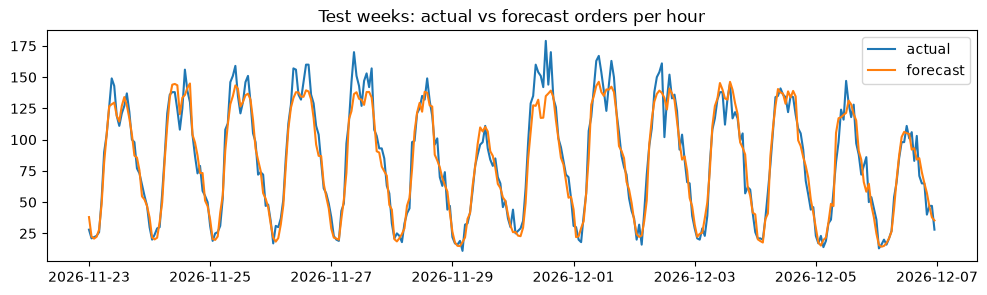

In [10]:
pred = best_model.predict(X_test)
test_mae = mae(y_test, pred)
test_base = mae(y_test, X_test["lag_168h_orders"])
print(f"TEST MAE model {test_mae}  vs  same-hour-last-week {test_base} "
      f"({100 * (1 - test_mae / test_base):.1f} % better)")  # fmt: skip
plt.figure(figsize=(12, 3))
plt.plot(test["timestamp"], y_test.values, label="actual")
plt.plot(test["timestamp"], pred, label="forecast")
plt.legend()
plt.title("Test weeks: actual vs forecast orders per hour")
plt.show()

## Step 10 — Save & report

In [11]:
joblib.dump(best_model, MODELS / "demand_v1.joblib")
report = {
    "model": "demand_v1",
    "algorithm": best_name,
    "features": FEATURES,
    "dataset_version": "v3",
    "validation_mae": results,
    "test_mae": test_mae,
    "test_baseline_mae": test_base,
}
(MODELS / "demand_v1_report.json").write_text(json.dumps(report, indent=2))
print("Saved models/demand_v1.joblib")
pd.Series(results, name="validation MAE").sort_values().head(8)

Saved models/demand_v1.joblib


Gradient Boosting lr=0.03 leaf=30    8.70
XGBoost lr=0.03 depth=3              8.76
Linear Regression                    8.82
Random Forest                        8.89
Gradient Boosting lr=0.03 leaf=10    8.95
Gradient Boosting                    8.96
XGBoost                              9.13
XGBoost lr=0.1 depth=3               9.25
Name: validation MAE, dtype: float64

## Summary

**What we predict:** how many orders will arrive in the **next hour** (time-series forecasting).

**Before (without this model):** planning by rules of thumb such as "same as this hour last week",
off by **10.3 orders per hour** on the test weeks.

**Best settings on validation:**

| Model / settings | val MAE (orders/h) |
|---|---|
| Gradient Boosting lr=0.03 leaf=30 | 8.7 |
| XGBoost lr=0.03 depth=3 | 8.76 |
| Linear Regression | 8.82 |
| Random Forest | 8.89 |
| Gradient Boosting lr=0.03 leaf=10 | 8.95 |
| Gradient Boosting | 8.96 |

| Test set (last 2 weeks, incl. Black Friday) | MAE (orders per hour) |
|---|---|
| Baseline: same hour last week | 10.3 |
| **Gradient Boosting lr=0.03 leaf=30 (demand_v1)** | **8.5** |

**What it shows**
- The forecast is **18 % more accurate** than "same hour last week".
- Demand has a daily rhythm, a weekly rhythm and a seasonal rise into November; calendar features plus
  recent history capture all three. Simple and boosted models are close: the signal is very regular.
- `05_demand_breakdown.ipynb` forecasts **where** (per zone) and **how urgent** (per priority).

**How it is used:** forecast at the start of every simulated hour (dashboard chart), saved with the real
count in the `predictions` table; in Phase 4 it decides charging and robot positioning.

**Saved:** `models/demand_v1.joblib`, `models/demand_v1_report.json`.